In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam

In [ ]:
TRAIN_PATH = "/content/drive/MyDrive/flower14/14 type flower/train"
VAL_PATH   = "/content/drive/MyDrive/flower14/14 type flower/val"

In [ ]:
IMG_SIZE = 32
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen   = ImageDataGenerator(rescale=1./255)

train_data = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_data = val_datagen.flow_from_directory(
    VAL_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

Found 13642 images belonging to 14 classes.
Found 98 images belonging to 14 classes.


In [ ]:
def reshape_for_rnn(generator):
    while True:
        x, y = next(generator)
        x = x.reshape(x.shape[0], IMG_SIZE, IMG_SIZE * 3)
        yield x, y

train_rnn = reshape_for_rnn(train_data)
val_rnn   = reshape_for_rnn(val_data)

In [ ]:
model = Sequential()

model.add(SimpleRNN(128, input_shape=(IMG_SIZE, IMG_SIZE*3)))
model.add(Dropout(0.3))

model.add(Dense(64, activation='relu'))
model.add(Dense(14, activation='softmax'))

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        28,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 14)             │           910 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,966 (148.30 KB)

 Trainable params: 37,966 (148.30 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
EPOCHS = 15

history = model.fit(
    train_rnn,
    steps_per_epoch=train_data.samples // BATCH_SIZE,
    validation_data=val_rnn,
    validation_steps=val_data.samples // BATCH_SIZE,
    epochs=EPOCHS
)

Epoch 1/15
426/426 ━━━━━━━━━━━━━━━━━━━━ 3589s 8s/step - accuracy: 0.1590 - loss: 2.4489 - val_accuracy: 0.2083 - val_loss: 2.0472
Epoch 2/15
426/426 ━━━━━━━━━━━━━━━━━━━━ 63s 148ms/step - accuracy: 0.2338 - loss: 2.1700 - val_accuracy: 0.2708 - val_loss: 1.9037
Epoch 3/15
426/426 ━━━━━━━━━━━━━━━━━━━━ 63s 148ms/step - accuracy: 0.2970 - loss: 2.0152 - val_accuracy: 0.3229 - val_loss: 1.8053
Epoch 4/15
426/426 ━━━━━━━━━━━━━━━━━━━━ 63s 149ms/step - accuracy: 0.3071 - loss: 1.9605 - val_accuracy: 0.3333 - val_loss: 1.8808
Epoch 5/15
426/426 ━━━━━━━━━━━━━━━━━━━━ 63s 147ms/step - accuracy: 0.3289 - loss: 1.9279 - val_accuracy: 0.3958 - val_loss: 1.7367
Epoch 6/15
426/426 ━━━━━━━━━━━━━━━━━━━━ 63s 149ms/step - accuracy: 0.3382 - loss: 1.9012 - val_accuracy: 0.2396 - val_loss: 1.9705
Epoch 7/15
426/426 ━━━━━━━━━━━━━━━━━━━━ 63s 147ms/step - accuracy: 0.2935 - loss: 2.0443 - val_accuracy: 0.3438 - val_loss: 1.6626
Epoch 8/15
426/426 ━━━━━━━━━━━━━━━━━━━━ 82s 192ms/step - accuracy: 0.3398 - loss: 1.

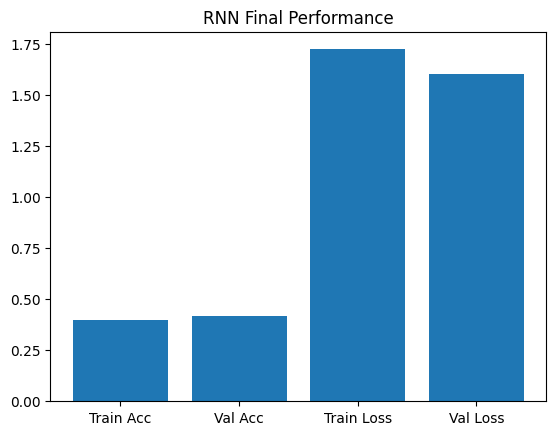

In [ ]:
train_acc = history.history['accuracy'][-1]
val_acc   = history.history['val_accuracy'][-1]
train_loss = history.history['loss'][-1]
val_loss   = history.history['val_loss'][-1]

labels = ['Train Acc', 'Val Acc', 'Train Loss', 'Val Loss']
values = [train_acc, val_acc, train_loss, val_loss]

plt.figure()
plt.bar(labels, values)
plt.title("RNN Final Performance")
plt.show()

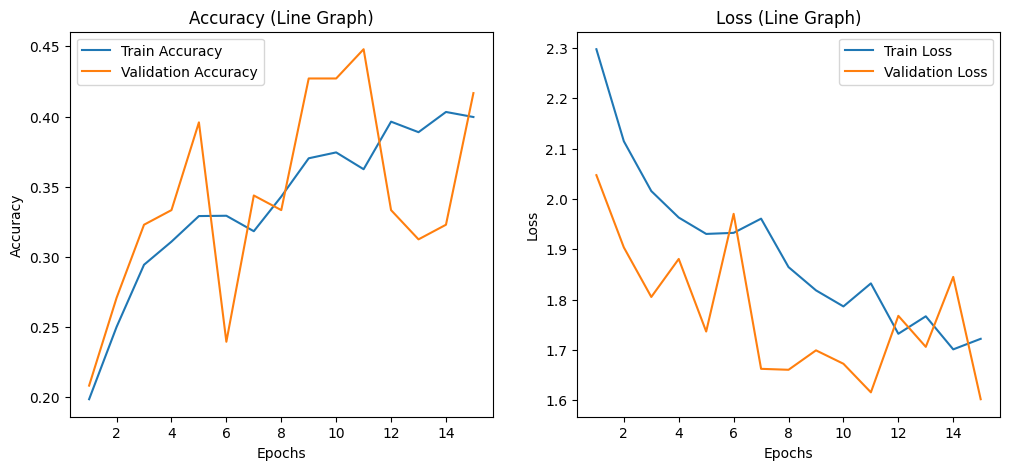

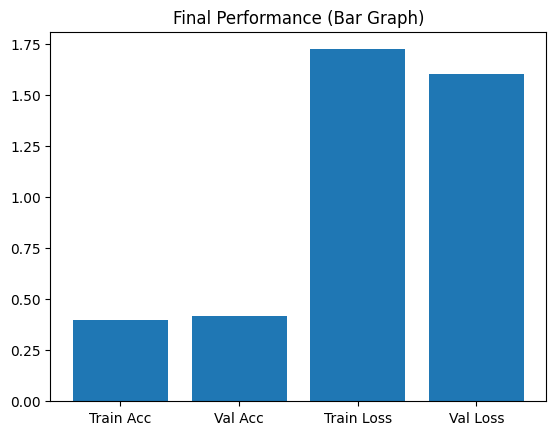

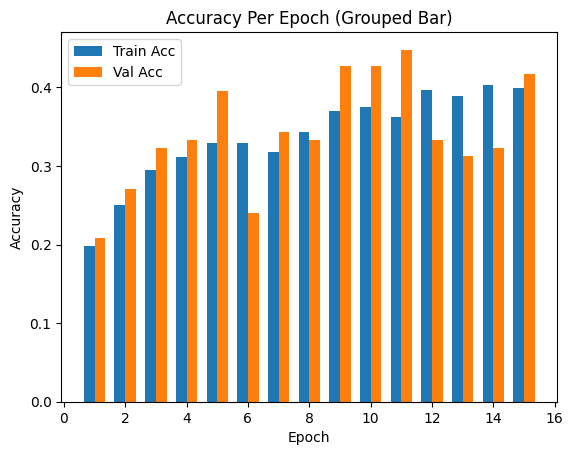

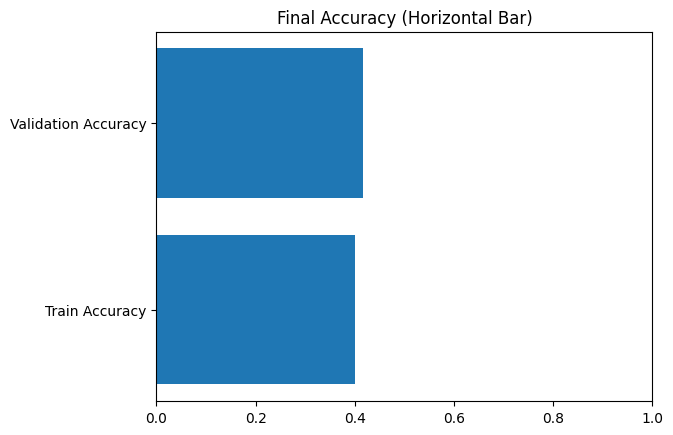

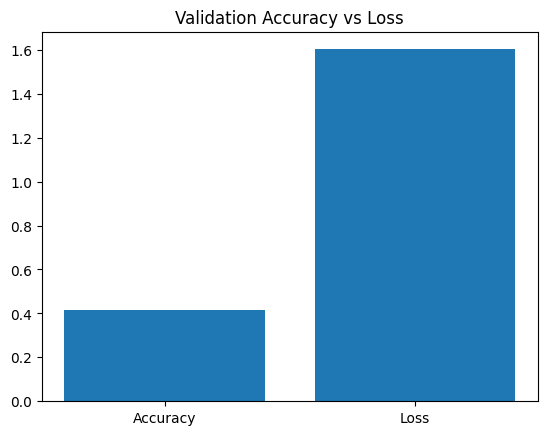

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(1, len(history.history['accuracy']) + 1)

train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
train_loss = history.history['loss']
val_loss = history.history['val_loss']

# -----------------------------
# 1️⃣ Line Graph (Accuracy & Loss)
# -----------------------------
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs, train_acc, label='Train Accuracy')
plt.plot(epochs, val_acc, label='Validation Accuracy')
plt.title('Accuracy (Line Graph)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs, train_loss, label='Train Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Loss (Line Graph)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()


# -----------------------------
# 2️⃣ Final Accuracy & Loss Bar Graph
# -----------------------------
plt.figure()
labels = ['Train Acc', 'Val Acc', 'Train Loss', 'Val Loss']
values = [train_acc[-1], val_acc[-1], train_loss[-1], val_loss[-1]]

plt.bar(labels, values)
plt.title('Final Performance (Bar Graph)')
plt.show()


# -----------------------------
# 3️⃣ Grouped Bar Graph Per Epoch (Accuracy)
# -----------------------------
width = 0.35

plt.figure()
plt.bar(epochs - width/2, train_acc, width, label='Train Acc')
plt.bar(epochs + width/2, val_acc, width, label='Val Acc')
plt.title('Accuracy Per Epoch (Grouped Bar)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


# -----------------------------
# 4️⃣ Horizontal Bar Graph
# -----------------------------
plt.figure()
plt.barh(['Train Accuracy', 'Validation Accuracy'],
         [train_acc[-1], val_acc[-1]])
plt.title('Final Accuracy (Horizontal Bar)')
plt.xlim(0,1)
plt.show()


# -----------------------------
# 5️⃣ Accuracy vs Loss Comparison
# -----------------------------
plt.figure()
plt.bar(['Accuracy', 'Loss'],
        [val_acc[-1], val_loss[-1]])
plt.title('Validation Accuracy vs Loss')
plt.show()